In [30]:
import sys
print(sys.executable)

/Users/aymanbelbachir/covid-ct-classifier/.venv/bin/python3


In [31]:
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from tqdm.auto import tqdm

In [43]:
DATA_ROOT = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
IMG_SIZE= 224
BATCH_SIZE= 16
EPOCHS= 25
LR = 1e-4
SEED =42

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Pytorch version", torch.__version__,"|device", device)

Pytorch version 2.14.1 |device mps


In [33]:
dataset= datasets.ImageFolder(DATA_ROOT)
classes = dataset.classes
print("Classes :", dataset.class_to_idx)
counts = Counter(dataset.targets)
for i, name in enumerate(classes):
    print(f"{name:5s} {counts[i]:6,} images")
print(f"Total : {len(dataset):,} images")
    

Classes : {'NiCT': 0, 'nCT': 1, 'pCT': 2}
NiCT   5,705 images
nCT    9,979 images
pCT    4,001 images
Total : 19,685 images


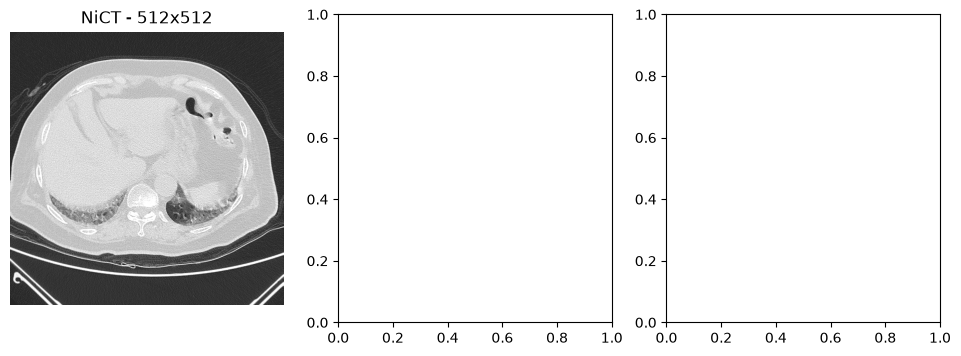

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, name in enumerate(classes):
    idx = random.choice([j for j, t in enumerate(dataset.targets) if t == i])
    path, _ = dataset.samples[idx]
    img = Image.open(path)
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"{name} - {img.size[0]}x{img.size[1]}")
    axes[i].axis("off")
    plt.show()

In [35]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])




In [36]:
path, label = dataset.samples[0]
print("Image :", path, "| classe :", classes[label])

image = Image.open(path).convert("RGB")
x = eval_transform(image)
print("Shape :", x.shape)
print("Min / max :", x.min().item(), x.max().item())

a = train_transform(image)
b = train_transform(image)
print("Train : identiques ?", torch.equal(a, b))

c = eval_transform(image)
d = eval_transform(image)
print("Eval : identiques ?", torch.equal(c, d))

Image : data/NiCT/NiCT1.jpg | classe : NiCT
Shape : torch.Size([3, 224, 224])
Min / max : -1.432913899421692 2.640000104904175
Train : identiques ? False
Eval : identiques ? True


In [37]:
rng = random.Random(SEED)

by_class = {i: [] for i in range(len(classes))}
for idx, label in enumerate(dataset.targets):
    by_class[label].append(idx)

train_idx, val_idx, test_idx = [], [], []
for label, idxs in by_class.items():
    rng.shuffle(idxs)
    n_train = int(0.70 * len(idxs))
    n_val = int(0.15 * len(idxs))
    train_idx += idxs[:n_train]
    val_idx += idxs[n_train:n_train + n_val]
    test_idx += idxs[n_train + n_val:]

print(f"Train : {len(train_idx):,} | Validation : {len(val_idx):,} | Test : {len(test_idx):,}")

Train : 13,778 | Validation : 2,951 | Test : 2,956


In [38]:
train_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=train_transform), train_idx)
val_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=eval_transform), val_idx)
test_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=eval_transform), test_idx)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=4, persistent_workers=True)
train_loader = DataLoader(train_ds, shuffle=True, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

images, labels = next(iter(train_loader))
print("Batch d'images :", images.shape)
print("Labels         :", labels)

Batch d'images : torch.Size([16, 3, 224, 224])
Labels         : tensor([2, 0, 1, 1, 1, 0, 2, 0, 2, 0, 1, 1, 1, 0, 0, 2])


In [39]:
head = nn.Sequential(
    nn.Linear(960, 1280),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(1280, len(classes)),
)
print(head)

Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=1280, out_features=3, bias=True)
)


In [40]:
model = models.mobilenet_v3_large(weights="DEFAULT")
print("Tête d'origine :")
print(model.classifier)

model.classifier = head
model = model.to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Paramètres entraînables : {n_params:,}")

Tête d'origine :
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)
Paramètres entraînables : 4,205,875


In [41]:
model.eval()
with torch.no_grad():
    outputs = model(images.to(device))

print("Sortie :", outputs.shape)
print("Logits (3 premières images) :")
print(outputs[:3])
print("Probabilités (3 premières images) :")
print(torch.softmax(outputs, dim=1)[:3])

Sortie : torch.Size([16, 3])
Logits (3 premières images) :
tensor([[ 0.0464, -0.1061, -0.0707],
        [ 0.0722, -0.0533, -0.0484],
        [ 0.0860, -0.1371, -0.0793]], device='mps:0')
Probabilités (3 premières images) :
tensor([[0.3639, 0.3124, 0.3237],
        [0.3612, 0.3186, 0.3202],
        [0.3777, 0.3022, 0.3202]], device='mps:0')


In [45]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

loss = criterion(outputs, labels.to(device))
print(f"Loss before training : {loss.item():.4f}")

Loss before training : 1.1038


In [47]:
def evaluate(model, loader):
    """Return the average loss and the accuracy of the model on a data loader."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            n += labels.size(0)

    return total_loss / n, correct / n


val_loss, val_acc = evaluate(model, val_loader)
print(f"Validation before training: loss {val_loss:.4f} | accuracy {val_acc:.2%}")

Validation before training: loss 1.1216 | accuracy 24.16%


In [49]:
def train_one_epoch(model, loader):
    """Train the model for one epoch and return the average loss and accuracy."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        n += labels.size(0)

    return total_loss / n, correct / n

In [51]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc = 0.0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    saved = ""
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), OUTPUT_DIR / "best_model.pth")
        saved = "  <- best, saved"

    print(f"Epoch {epoch:2d}/{EPOCHS} | "
          f"train loss {train_loss:.4f} acc {train_acc:.2%} | "
          f"val loss {val_loss:.4f} acc {val_acc:.2%} | "
          f"{time.time() - t0:.0f}s{saved}")

print(f"Training done in {(time.time() - start) / 60:.1f} min | best val accuracy: {best_acc:.2%}")

Training:   0%|          | 0/862 [00:00<?, ?it/s]

Epoch  1/25 | train loss 0.0314 acc 98.74% | val loss 0.0138 acc 99.39% | 143s  <- best, saved


Training:   0%|          | 0/862 [00:00<?, ?it/s]

Epoch  2/25 | train loss 0.0329 acc 98.85% | val loss 0.0232 acc 99.53% | 143s  <- best, saved


Training:   0%|          | 0/862 [00:00<?, ?it/s]

...

Epoch 23/25 | train loss 0.0251 acc 99.13% | val loss 0.0286 acc 99.39% | 145s


Training:   0%|          | 0/862 [00:00<?, ?it/s]

Epoch 24/25 | train loss 0.0250 acc 99.03% | val loss 0.0162 acc 99.49% | 145s


Training:   0%|          | 0/862 [00:00<?, ?it/s]

Epoch 25/25 | train loss 0.0239 acc 99.07% | val loss 0.0144 acc 99.49% | 145s
Training done in 97.0 min | best val accuracy: 99.56%


In [52]:
model.load_state_dict(torch.load(OUTPUT_DIR / "best_model.pth", map_location=device))

val_loss, val_acc = evaluate(model, val_loader)
test_loss, test_acc = evaluate(model, test_loader)

print(f"Validation: loss {val_loss:.4f} | accuracy {val_acc:.2%}")
print(f"Test:       loss {test_loss:.4f} | accuracy {test_acc:.2%}")

Validation: loss 0.0177 | accuracy 99.56%
Test:       loss 0.0069 | accuracy 99.63%


In [53]:
def get_predictions(model, loader):
    """Return all predictions and true labels of the model on a data loader."""
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            all_preds.append(outputs.argmax(dim=1).cpu())
            all_labels.append(labels)
    return torch.cat(all_preds), torch.cat(all_labels)


preds, true = get_predictions(model, test_loader)

n_classes = len(classes)
cm = torch.zeros(n_classes, n_classes, dtype=torch.int64)
for t, p in zip(true, preds):
    cm[t, p] += 1

print("Rows = true class, columns = predicted class\n")
print("      " + "".join(f"{c:>7s}" for c in classes))
for i, c in enumerate(classes):
    print(f"{c:5s} " + "".join(f"{cm[i, j].item():7d}" for j in range(n_classes)))

print()
for i, c in enumerate(classes):
    recall = cm[i, i].item() / cm[i].sum().item()
    print(f"{c:5s} correctly classified: {recall:.2%}")

Rows = true class, columns = predicted class

         NiCT    nCT    pCT
NiCT      856      1      0
nCT         7   1490      1
pCT         2      0    599

NiCT  correctly classified: 99.88%
nCT   correctly classified: 99.47%
pCT   correctly classified: 99.67%


In [54]:
def predict(image_path, model):
    """Return the predicted probability of each class for one image."""
    image = Image.open(image_path).convert("RGB")
    x = eval_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]
    return probs.cpu()

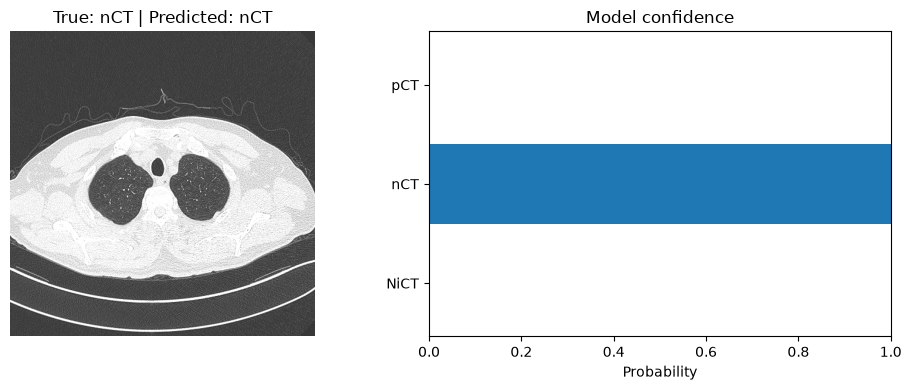

NiCT  0.00%
nCT   100.00%
pCT   0.00%


In [55]:
idx = random.choice(test_idx)
path, label = dataset.samples[idx]
probs = predict(path, model)
pred = probs.argmax().item()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.imshow(Image.open(path), cmap="gray")
ax1.set_title(f"True: {classes[label]} | Predicted: {classes[pred]}")
ax1.axis("off")

ax2.barh(classes, probs.numpy())
ax2.set_xlim(0, 1)
ax2.set_xlabel("Probability")
ax2.set_title("Model confidence")

plt.tight_layout()
plt.show()

for c, p in zip(classes, probs):
    print(f"{c:5s} {p.item():.2%}")